In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("data/annotations_RPN_75mm_final.csv")
df

,tumor_id,case_id,tumor_instance,kidney_instance,calculated_diameter_mm,spacing_z,spacing_y,spacing_x,position,invasion,radius_pts,approved_for_training,Unnamed: 12
0,case_00000_t1,case_00000,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,31.20,0.5,0.919922,0.919922,Peripheral,Noninvasive,0.0,True,NaN
1,case_00001_t1,case_00001,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,18.06,0.5,0.798828,0.798828,Peripheral,Noninvasive,0.0,True,NaN
2,case_00001_t2,case_00001,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,25.34,0.5,0.798828,0.798828,Peripheral,Invasive,0.0,True,NaN
3,case_00002_t1,case_00002,tumor_instance-1_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,49.03,1.0,0.939453,0.939453,Peripheral,Semi-invasive,1.0,True,NaN
4,case_00003_t1,case_00003,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,32.72,1.0,0.855469,0.855469,Peripheral,Noninvasive,1.0,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
429,case_00586_t3,case_00586,tumor_instance-3_annotation-1.nii.gz,kidney_instance-2_annotation-1.nii.gz,20.16,3.0,0.781250,0.781250,Peripheral,Noninvasive,0.0,True,NaN
430,case_00586_t1,case_00586,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,20.73,3.0,0.781250,0.781250,Peripheral,Noninvasive,0.0,True,NaN
431,case_00586_t2,case_00586,tumor_instance-2_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,27.98,3.0,0.781250,0.781250,Peripheral,Noninvasive,0.0,True,NaN
432,case_00587_t1,case_00587,tumor_instance-1_annotation-1.nii.gz,kidney_instance-1_annotation-1.nii.gz,21.96,5.0,0.800781,0.800781,Peripheral,Noninvasive,0.0,True,NaN


position
Peripheral    321
Hilar          61
Central        27
Name: count, dtype: int64


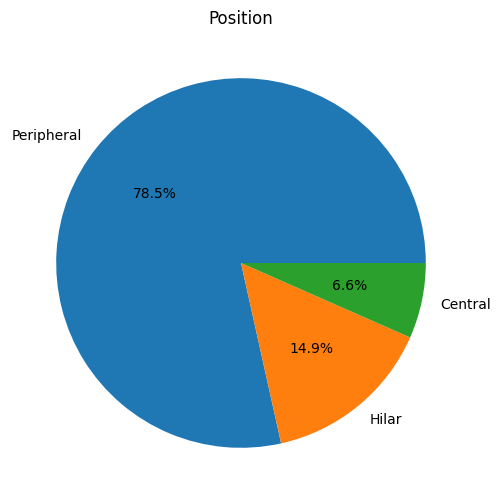

invasion
Noninvasive      164
Semi-invasive    148
Invasive          96
Name: count, dtype: int64


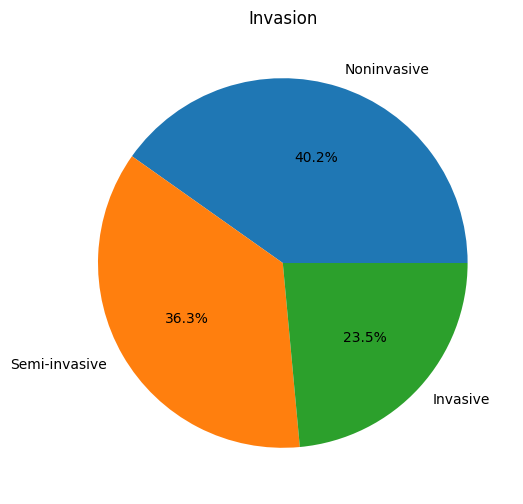

radius_pts
1.0    183
0.0    157
2.0     65
Name: count, dtype: int64


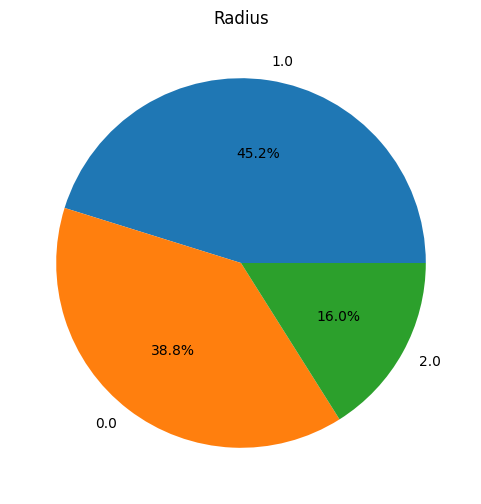

In [7]:
counts = df["position"].value_counts()
print(counts)

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%')
plt.title("Position")
plt.show()

counts = df["invasion"].value_counts()
print(counts)

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%')
plt.title("Invasion")
plt.show()

counts = df["radius_pts"].value_counts()
print(counts)

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%')
plt.title("Radius")
plt.show()


/tmp/ipykernel_28682/3920647882.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(counts.index.astype(str), rotation=15, ha='right')


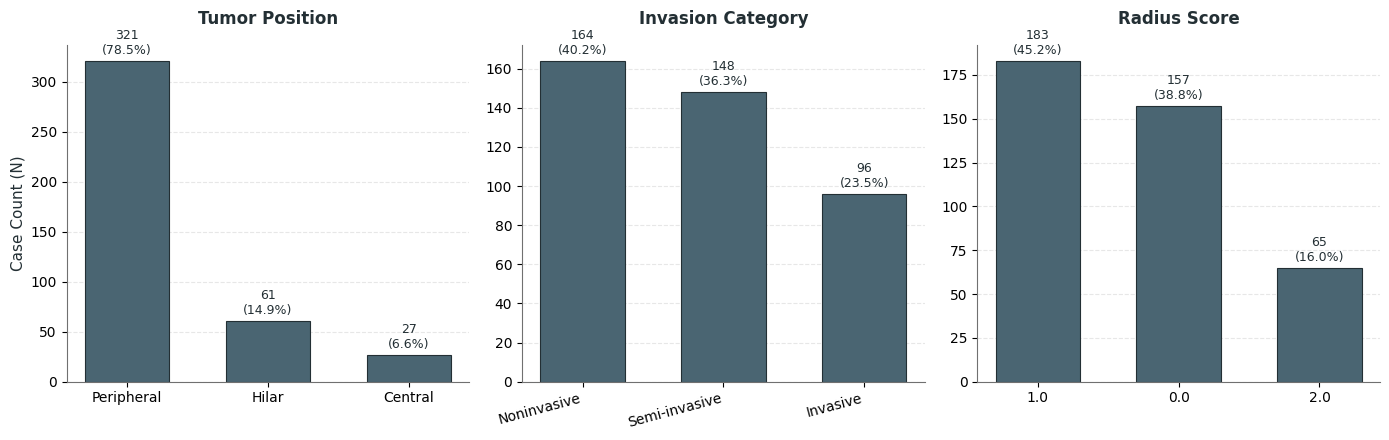

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_scientific_distribution(df):
    # Set an academic, clean aesthetic
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['xtick.labelsize'] = 10
    plt.rcParams['ytick.labelsize'] = 10
    plt.rcParams['axes.labelsize'] = 11
    
    # 1x3 Grid setup
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
    columns = ['position', 'invasion', 'radius_pts']
    titles = ['Tumor Position', 'Invasion Category', 'Radius Score']
    
    # Use a single, academic muted slate blue color
    academic_color = '#4A6572' 
    
    for i, col in enumerate(columns):
        ax = axes[i]
        
        # Clean data and calculate frequencies
        counts = df[col].dropna().value_counts()
        total = counts.sum()
        
        # Plot bars
        bars = ax.bar(counts.index.astype(str), counts.values, color=academic_color, width=0.6, edgecolor='#232F34', linewidth=0.8)
        
        # Remove top and right borders (spines) for a clean scientific look
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#707070')
        ax.spines['bottom'].set_color('#707070')
        
        # Title and Labels
        ax.set_title(titles[i], fontsize=12, weight='bold', pad=15, color='#232F34')
        ax.set_ylabel('Case Count (N)' if i == 0 else '', color='#232F34')
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.set_axisbelow(True) # Put grid lines behind bars
        
        # Add exact Count and Percentage above each bar
        for bar in bars:
            height = bar.get_height()
            percentage = (height / total) * 100
            ax.annotate(f'{int(height)}\n({percentage:.1f}%)',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, color='#232F34')
            
        # Rotate x-labels slightly if they are long words
        if col == 'invasion':
            ax.set_xticklabels(counts.index.astype(str), rotation=15, ha='right')

    plt.tight_layout()
    plt.show()

# Run the visualizer
plot_scientific_distribution(df)

In [12]:
def generate_latex_table(df):
    columns = ['position', 'invasion', 'radius_pts']
    map_names = {'position': 'Position', 'invasion': 'Invasion', 'radius_pts': 'Radius Score'}
    
    latex_str = []
    latex_str.append(r"\begin{table}[htbp]")
    latex_str.append(r"\centering")
    latex_str.append(r"\caption{Distribution of Tumor Characteristics across the Dataset}")
    latex_str.append(r"\label{tab:dataset_distribution}")
    latex_str.append(r"\begin{tabular}{llrr}")
    latex_str.append(r"\toprule")
    latex_str.append(r"\textbf{Variable} & \textbf{Category} & \textbf{Count (N)} & \textbf{\% Extraction} \\")
    latex_str.append(r"\midrule")
    
    for col in columns:
        counts = df[col].dropna().value_counts()
        total = counts.sum()
        
        first_row = True
        for cat, count in counts.items():
            pct = (count / total) * 100
            # Clean category names for latex encoding
            clean_cat = str(cat).replace('_', r'\_').capitalize()
            var_name = map_names[col] if first_row else ""
            
            latex_str.append(f"{var_name} & {clean_cat} & {count} & {pct:.1f}\\% \\\\")
            first_row = False
        latex_str.append(r"\hline") # subtle line between variables
        
    # Remove the last trailing hline and replace with bottomrule
    latex_str.pop()
    latex_str.append(r"\bottomrule")
    latex_str.append(r"\end{tabular}")
    latex_str.append(r"\end{table}")
    
    print("\n".join(latex_str))

# Run the generator
generate_latex_table(df)

\begin{table}[htbp]
\centering
\caption{Distribution of Tumor Characteristics across the Dataset}
\label{tab:dataset_distribution}
\begin{tabular}{llrr}
\toprule
\textbf{Variable} & \textbf{Category} & \textbf{Count (N)} & \textbf{\% Extraction} \\
\midrule
Position & Peripheral & 321 & 78.5\% \\
 & Hilar & 61 & 14.9\% \\
 & Central & 27 & 6.6\% \\
\hline
Invasion & Noninvasive & 164 & 40.2\% \\
 & Semi-invasive & 148 & 36.3\% \\
 & Invasive & 96 & 23.5\% \\
\hline
Radius Score & 1.0 & 183 & 45.2\% \\
 & 0.0 & 157 & 38.8\% \\
 & 2.0 & 65 & 16.0\% \\
\bottomrule
\end{tabular}
\end{table}
